In [5]:
import os, re, subprocess, sys
from pathlib import Path

In [ ]:
#Java aparece só porque o PySpark precisa dele por baixo. O Spark é um motor escrito em Scala e roda numa JVM
#I-CSV vindo de um sistema legado,convergência
#DAG orquestra 4 etapas
#II-ETL = extrair(raw),transformar,validar,publicar
# pandas-on-Spark (Parametrização"limpeza"),Spark SQL (regra de negócio),DataFrame API (conferência)
#III-TELA: login (CPF + senha)  →  menu do aluno:
# Situação da inscrição (deferida / indeferida) ·  Protocolos (abrir carteirinha) ·  Declaração ·  Canvas
#IV -  1) Preparar · 2) Fontes · 3) Rodar o ETL etapa por etapa · 4) Explorar com Spark SQL / pandas-on-Spark · 5) Usar o portal (tela) · 6) Experimentos · 7) Airflow (DAG + interface) · 8) Revisão.

In [7]:
#PyArrow (pandas-on-Spark)
#ipywidgets (tela) e reportlab (PDF da declaração)
HOME = Path("/content/portal_aluno"); HOME.mkdir(parents=True, exist_ok=True)
os.environ["PORTAL_HOME"] = str(HOME)

In [ ]:
#verificar versao
def java_major():
    try:
        saida = subprocess.run(["java", "-version"], capture_output=True, text=True).stderr
        m = re.search(r'version "(\d+)', saida)
        return int(m.group(1)) if m else 0
    except FileNotFoundError:
        return 0

if java_major() < 17:
    subprocess.run(["apt-get", "-qq", "install", "-y", "openjdk-17-jdk-headless"], check=True)
    os.environ["JAVA_HOME"] = "/usr/lib/jvm/java-17-openjdk-amd64"
    os.environ["PATH"] = os.environ["JAVA_HOME"] + "/bin:" + os.environ["PATH"]
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "pyspark==4.0.1", "pyarrow", "ipywidgets", "reportlab"], check=True)

sys.path.insert(0, str(HOME))
print("Java", java_major(), "| Python", sys.version.split()[0], "| pasta do projeto:", HOME)

Java 21 | Python 3.13.16 | pasta do projeto: /content/portal_aluno


## 2. Código do projeto (4 módulos)
Cada célula grava um arquivo `.py` em `/content/portal_aluno/`. **Leia com calma**: é o código que o Airflow vai orquestrar.

| Arquivo | Papel |
|---|---|
| `portal_seguranca.py` | CPF (dígitos verificadores), máscara LGPD, hash de senha com scrypt |
| `portal_modelo.py` | Entidades do UML como *dataclasses* |
| `portal_etl.py` | O ETL: extrair → transformar (PySpark) → validar → publicar |
| `portal_app.py` | Login, regras do aluno, declaração, protocolos e a tela |

In [ ]:
%%writefile /content/portal_aluno/portal_seguranca.py

import hashlib
import hmac
import os
import re

def somente_digitos(texto):
    return re.sub(r"\D", "", texto or "")


def cpf_valido(cpf):
   
    c = somente_digitos(cpf)
    if len(c) != 11 or c == c[0] * 11:
        return False
    for tamanho in (9, 10):
        soma = sum(int(c[i]) * (tamanho + 1 - i) for i in range(tamanho))
        digito = (soma * 10 % 11) % 10
        if digito != int(c[tamanho]):
            return False
    return True


def gerar_cpf(base9):
    
    d = [int(x) for x in f"{base9:09d}"]
    for tamanho in (9, 10):
        soma = sum(d[i] * (tamanho + 1 - i) for i in range(tamanho))
        d.append((soma * 10 % 11) % 10)
    return "".join(map(str, d))


def formatar_cpf(cpf):
    c = somente_digitos(cpf)
    return f"{c[:3]}.{c[3:6]}.{c[6:9]}-{c[9:]}"


def mascarar_cpf(cpf):
   
    c = somente_digitos(cpf)
    return f"***.{c[3:6]}.{c[6:9]}-**"


def hash_senha(senha, salt_hex=None):

    salt = bytes.fromhex(salt_hex) if salt_hex else os.urandom(16)
    h = hashlib.scrypt(senha.encode("utf-8"), salt=salt, n=2**14, r=8, p=1, dklen=32)
    return h.hex(), salt.hex()


def senha_confere(senha, hash_hex, salt_hex):
    h, _ = hash_senha(senha, salt_hex)
    return hmac.compare_digest(h, hash_hex)   # comparação em tempo constante

Writing /content/portal_aluno/portal_seguranca.py


In [10]:
#Entidades
%%writefile /content/portal_aluno/portal_modelo.py
"""Entidades do domínio (espelham o diagrama de classes UML do sistema de matrícula).

Usuario  <|--  Aluno | Professor | Secretaria      (herança do diagrama)
Curso 1 --- 1..* Disciplina                          (Curso.Disciplinas)
Aluno 1 --- * Matricula * --- 1 Disciplina           (histórico de notas)
Aluno 1 --- * Inscricao * --- 1 Disciplina           (pedido de inscrição, deferido ou não)
Aluno 1 --- * Protocolo                              (solicitações: carteirinha, declaração...)
"""
from dataclasses import dataclass
from datetime import date, datetime
from typing import Optional


@dataclass(kw_only=True)
class Usuario:
    cpf: str
    nome: str
    perfil: str            # ALUNO | PROFESSOR | SECRETARIA


@dataclass(kw_only=True)
class Aluno(Usuario):
    matricula: int
    curso_id: str
    origem: str = ""


@dataclass(kw_only=True)
class Professor(Usuario):
    pass


@dataclass(kw_only=True)
class Secretaria(Usuario):
    pass


@dataclass(kw_only=True)
class Curso:
    curso_id: str
    nome: str
    creditos: int
    inicio_matricula: date
    termino_matricula: date


@dataclass(kw_only=True)
class Disciplina:
    disciplina_id: str
    nome: str
    curso_id: str
    creditos: int
    optativa: bool = False
    ativa: bool = True


@dataclass(kw_only=True)
class Matricula:
    """Linha do histórico: o aluno cursou/está cursando uma disciplina."""
    matricula: int
    disciplina_id: str
    semestre: str
    nota: Optional[float]          # None = ainda sem nota (cursando)
    resultado: str                 # APROVADO | REPROVADO | CURSANDO


@dataclass(kw_only=True)
class Inscricao:
    """Pedido do aluno para se inscrever em uma disciplina no próximo semestre."""
    protocolo: str
    matricula: int
    disciplina_id: str
    semestre: str
    situacao: str = "EM_ANALISE"   # DEFERIDA | INDEFERIDA (decidida pelo ETL/regra)
    parecer: str = ""


@dataclass(kw_only=True)
class Protocolo:
    protocolo: str
    matricula: int
    tipo: str                      # INSCRICAO_DISCIPLINA | CARTEIRINHA | DECLARACAO
    situacao: str                  # ABERTO | EM_ANALISE | CONCLUIDO | INDEFERIDO
    parecer: str
    aberto_em: datetime

Writing /content/portal_aluno/portal_modelo.py


In [ ]:
%%writefile /content/portal_aluno/portal_etl.py
"""ETL do Portal do Aluno.

    python portal_etl.py extrair | transformar | validar | publicar | tudo

extrair      copia os CSVs do sistema legado para a camada RAW (um snapshot por execução) + manifesto
transformar  PySpark: pandas-on-Spark (limpeza) + Spark SQL (regra de negócio) + DataFrame API; grava CURATED (Parquet)
validar      qualidade de dados + reconciliação das 3 implementações da regra; falha o pipeline se algo estiver errado
publicar     carrega o banco de serviço (SQLite) em uma transação; não apaga os protocolos abertos pelo aluno
"""
import hashlib
import json
import os
import shutil
import sqlite3
import sys
import time
from datetime import datetime
from pathlib import Path

import pandas as pd

sys.path.insert(0, str(Path(__file__).resolve().parent))
from portal_seguranca import cpf_valido, somente_digitos   # noqa: E402

HOME = Path(os.environ.get("PORTAL_HOME", "/content/portal_aluno"))
FONTES, RAW, CUR, DB = HOME / "fontes", HOME / "lake" / "raw", HOME / "lake" / "curated", HOME / "portal.db"

#  REGRA DE NEGÓCIO 
NOTA_C = 6.0     # "abaixo do conceito C" = nota menor que 6,0
LIMITE = 2       # com 2 ou mais disciplinas abaixo de C o aluno fica INATIVO

ARQUIVOS = {
    "usuarios": ["cpf", "nome", "perfil", "senha_hash", "salt"],
    "alunos": ["matricula", "cpf", "nome", "curso_id", "origem", "email"],
    "cursos": ["curso_id", "nome", "creditos", "inicio_matricula", "termino_matricula"],
    "disciplinas": ["disciplina_id", "nome", "curso_id", "creditos", "optativa", "ativa"],
    "historico": ["matricula", "disciplina_id", "semestre", "nota", "resultado"],
    "inscricoes": ["inscricao_id", "matricula", "disciplina_id", "semestre", "protocolo", "data"],
    "protocolos": ["protocolo", "matricula", "tipo", "situacao", "parecer", "aberto_em"],
}


def log(msg):
    print(f"[{datetime.now():%H:%M:%S}] {msg}", flush=True)


def get_spark():
    os.environ["PYSPARK_PYTHON"] = sys.executable          # worker usa o mesmo Python (com pyarrow)
    os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
    os.environ["PYARROW_IGNORE_TIMEZONE"] = "1"
    from pyspark.sql import SparkSession
    spark = (SparkSession.builder.master("local[2]").appName("portal-aluno-etl")
             .config("spark.ui.enabled", "false")
             .config("spark.sql.session.timeZone", "UTC")
             .config("spark.sql.ansi.enabled", "false")      # nota inválida vira null (e a pandas API exige ANSI off)
             .config("spark.sql.shuffle.partitions", "4").getOrCreate())
    spark.sparkContext.setLogLevel("ERROR")
    return spark


#  1 EXTRACT 
def extrair():
    pasta = RAW / f"ingestao={datetime.now():%Y%m%d_%H%M%S_%f}"      # 1 pasta por execução (sem colisão)
    pasta.mkdir(parents=True)
    manifesto = []
    for nome, colunas in ARQUIVOS.items():
        origem = FONTES / f"{nome}.csv"
        if not origem.exists():
            raise FileNotFoundError(f"fonte ausente: {origem}")
        cabecalho = origem.read_text(encoding="utf-8").splitlines()[0].split(";")
        if cabecalho != colunas:
            raise ValueError(f"{nome}.csv: cabeçalho inesperado {cabecalho} (esperado {colunas})")
        shutil.copy(origem, pasta / origem.name)
        linhas = len(origem.read_text(encoding="utf-8").splitlines()) - 1
        manifesto.append({"arquivo": origem.name, "linhas": linhas, "sha256": hashlib.sha256(origem.read_bytes()).hexdigest()[:12]})
        log(f"extrair: {origem.name:16} {linhas:>3} linhas")
    (pasta / "_manifesto.json").write_text(json.dumps(manifesto, indent=1), encoding="utf-8")
    (RAW / "_ultima.txt").write_text(pasta.name)
    log(f"extrair: RAW -> {pasta.name}")


#  2 TRANSFORM
def transformar():
    from pyspark.sql import functions as F
    spark = get_spark()
    import pyspark.pandas as ps
    raw = RAW / (RAW / "_ultima.txt").read_text().strip()
    injetar = os.environ.get("PORTAL_INJETAR_ERRO", "").strip().lower() in ("1", "true")

    # (a) pandas-on-Spark: limpeza do histórico com a sintaxe do pandas, executada pelo Spark 
    hist = ps.read_csv(str(raw / "historico.csv"), sep=";", dtype=str)
    hist["matricula"] = hist["matricula"].str.strip()
    hist["disciplina_id"] = hist["disciplina_id"].str.strip().str.upper()
    hist["resultado"] = hist["resultado"].str.strip().str.upper()
    hist["nota"] = hist["nota"].str.strip().str.replace(",", ".").astype(float)      # "7,5" -> 7.5 ; "N/D" -> null
    log(f"transformar: histórico limpo (pandas-on-Spark): {len(hist)} linhas, {int(hist['nota'].isnull().sum())} sem nota válida")
    hist_sdf = hist.to_spark()
    if injetar:
        log("transformar: !!! injetando nota inválida (11,0) para testar a validação")
        extra = spark.sql("SELECT '2026003' AS matricula, 'ED01' AS disciplina_id, '2026.1' AS semestre, "
                          "CAST(11.0 AS DOUBLE) AS nota, 'APROVADO' AS resultado")
        hist_sdf = hist_sdf.unionByName(extra)

    #(b) demais tabelas: PySpark DataFrame 
    def ler(nome):
        return spark.read.csv(str(raw / f"{nome}.csv"), header=True, sep=";")

    usuarios = ler("usuarios").withColumn("cpf", F.regexp_replace("cpf", r"[^0-9]", ""))
    alunos = (ler("alunos").withColumn("cpf", F.regexp_replace("cpf", r"[^0-9]", ""))
              .withColumn("nome", F.initcap(F.trim("nome"))).withColumn("matricula", F.trim("matricula")))
    disciplinas = ler("disciplinas").withColumn("nome", F.trim("nome"))
    cursos = ler("cursos")
    inscricoes = ler("inscricoes").withColumn("matricula", F.trim("matricula"))
    protocolos = (ler("protocolos").withColumn("situacao", F.upper(F.trim("situacao")))
                  .withColumn("tipo", F.upper(F.trim("tipo"))).withColumn("matricula", F.trim("matricula")))

    for nome, df in [("historico_limpo", hist_sdf), ("alunos", alunos), ("disciplinas", disciplinas), ("inscricoes", inscricoes)]:
        df.createOrReplaceTempView(nome)

    #  (c) Spark SQL: a regra de negócio 
    aluno_status = spark.sql(f"""
        WITH abaixo AS (
            SELECT h.matricula, d.nome AS disciplina, h.nota
            FROM historico_limpo h JOIN disciplinas d ON d.disciplina_id = h.disciplina_id
            WHERE h.nota IS NOT NULL AND h.nota < {NOTA_C}
        ), agg AS (
            SELECT matricula, COUNT(*) AS qtd_abaixo_c,
                   array_join(array_sort(collect_list(
                       concat(disciplina, ' (', replace(format_string('%.1f', nota), '.', ','), ')'))), '; ') AS lista_abaixo_c
            FROM abaixo GROUP BY matricula
        )
        SELECT a.matricula, a.cpf, a.nome, a.curso_id,
               CAST(COALESCE(g.qtd_abaixo_c, 0) AS INT) AS qtd_abaixo_c,
               g.lista_abaixo_c,
               COALESCE(g.qtd_abaixo_c, 0) < {LIMITE} AS ativo
        FROM alunos a LEFT JOIN agg g ON g.matricula = a.matricula
    """)
    aluno_status.createOrReplaceTempView("aluno_status")

    inscricao_detalhe = spark.sql(f"""
        SELECT i.protocolo, i.matricula, d.nome AS disciplina, i.semestre, i.data,
               CASE WHEN s.ativo THEN 'DEFERIDA' ELSE 'INDEFERIDA' END AS situacao,
               s.ativo AS ativo,
               CASE WHEN s.ativo
                    THEN 'Inscrição deferida: o aluno está ativo (menos de {LIMITE} disciplinas com nota abaixo de C).'
                    ELSE concat('Inscrição indeferida: o aluno possui ', s.qtd_abaixo_c,
                                ' disciplinas com nota abaixo de C (6,0): ', s.lista_abaixo_c, '.') END AS parecer
        FROM inscricoes i
        JOIN disciplinas d ON d.disciplina_id = i.disciplina_id
        JOIN aluno_status s ON s.matricula = i.matricula
    """)

    historico_abaixo_c = spark.sql(f"""
        SELECT h.matricula, d.nome AS disciplina, h.semestre, h.nota
        FROM historico_limpo h JOIN disciplinas d ON d.disciplina_id = h.disciplina_id
        WHERE h.nota IS NOT NULL AND h.nota < {NOTA_C}
    """)

    #  (d) reconciliação: a MESMA regra por mais 2 caminhos (DataFrame API e pandas-on-Spark) 
    api = {r["matricula"]: r["count"] for r in hist_sdf.filter((F.col("nota").isNotNull()) & (F.col("nota") < NOTA_C))
           .groupBy("matricula").count().collect()}
    h2 = hist[hist["nota"].notnull()]
    pandas_on_spark = h2.assign(ab=(h2["nota"] < NOTA_C).astype(int)).groupby("matricula")["ab"].sum().to_pandas().to_dict()
    sql = {r["matricula"]: r["qtd_abaixo_c"] for r in aluno_status.collect()}
    recon = {m: {"sql": int(sql.get(m, 0)), "dataframe_api": int(api.get(m, 0)), "pandas_on_spark": int(pandas_on_spark.get(m, 0))}
             for m in sql}

    # (e) grava CURATED (Parquet) 
    CUR.mkdir(parents=True, exist_ok=True)
    saidas = {"aluno_status": aluno_status, "inscricao_detalhe": inscricao_detalhe, "historico_abaixo_c": historico_abaixo_c,
              "historico": hist_sdf, "usuarios": usuarios, "alunos": alunos, "disciplinas": disciplinas, "cursos": cursos,
              "protocolos": protocolos}
    for nome, df in saidas.items():
        df.coalesce(1).write.mode("overwrite").parquet(str(CUR / nome))
        log(f"transformar: curated/{nome:20} {df.count():>3} linhas")
    (CUR / "reconciliacao.json").write_text(json.dumps(recon, indent=1))
    spark.stop()


# 3. VALIDAR 
def ler_curated(nome):
    return pd.read_parquet(CUR / nome)


def validar():
    erros = []
    status, insc = ler_curated("aluno_status"), ler_curated("inscricao_detalhe")
    hist, usuarios = ler_curated("historico"), ler_curated("usuarios")
    disc = ler_curated("disciplinas")

    invalidos = [c for c in pd.concat([status["cpf"], usuarios["cpf"]]) if not cpf_valido(c)]
    if invalidos:
        erros.append(f"CPF inválido: {invalidos}")
    fora = hist[hist["nota"].notnull() & ~hist["nota"].between(0, 10)]
    if len(fora):
        erros.append(f"nota fora de 0-10: {fora[['matricula', 'disciplina_id', 'nota']].to_dict('records')}")
    if status["matricula"].duplicated().any():
        erros.append("matrícula duplicada em aluno_status")
    orfas = set(insc["matricula"]) - set(status["matricula"])
    if orfas:
        erros.append(f"inscrições sem aluno: {orfas}")
    if set(hist["disciplina_id"]) - set(disc["disciplina_id"]):
        erros.append(f"histórico com disciplina desconhecida: {set(hist['disciplina_id']) - set(disc['disciplina_id'])}")
    incoerentes = status[status["ativo"] != (status["qtd_abaixo_c"] < LIMITE)]
    if len(incoerentes):
        erros.append(f"campo 'ativo' incoerente com a regra: {incoerentes['matricula'].tolist()}")
    recon = json.loads((CUR / "reconciliacao.json").read_text())
    divergentes = {m: v for m, v in recon.items() if len(set(v.values())) != 1}
    if divergentes:
        erros.append(f"as 3 implementações da regra divergem: {divergentes}")

    log(f"validar: {len(status)} alunos | {len(insc)} inscrições | {len(hist)} linhas de histórico | reconciliação 3 métodos OK={not divergentes}")
    if erros:
        for e in erros:
            log(f"validar: ERRO -> {e}")
        raise SystemExit(f"Validação falhou ({len(erros)} erro(s))")
    log("validar: tudo certo")


# 4.LOAD 
DDL = """
CREATE TABLE IF NOT EXISTS usuario(cpf TEXT PRIMARY KEY, nome TEXT, perfil TEXT, senha_hash TEXT, salt TEXT,
                                   tentativas_falhas INTEGER DEFAULT 0, bloqueado_ate TEXT);
CREATE TABLE IF NOT EXISTS aluno(matricula TEXT PRIMARY KEY, cpf TEXT, nome TEXT, curso_id TEXT);
CREATE TABLE IF NOT EXISTS curso(curso_id TEXT PRIMARY KEY, nome TEXT, creditos INT, inicio_matricula TEXT, termino_matricula TEXT);
CREATE TABLE IF NOT EXISTS disciplina(disciplina_id TEXT PRIMARY KEY, nome TEXT, curso_id TEXT, creditos INT);
CREATE TABLE IF NOT EXISTS aluno_status(matricula TEXT PRIMARY KEY, cpf TEXT, nome TEXT, curso_id TEXT, qtd_abaixo_c INT, lista_abaixo_c TEXT, ativo INT);
CREATE TABLE IF NOT EXISTS inscricao_detalhe(protocolo TEXT PRIMARY KEY, matricula TEXT, disciplina TEXT, semestre TEXT, data TEXT,
                                             situacao TEXT, ativo INT, parecer TEXT);
CREATE TABLE IF NOT EXISTS historico_abaixo_c(matricula TEXT, disciplina TEXT, semestre TEXT, nota REAL);
CREATE TABLE IF NOT EXISTS protocolo(protocolo TEXT PRIMARY KEY, matricula TEXT, tipo TEXT, situacao TEXT, parecer TEXT, aberto_em TEXT);
CREATE TABLE IF NOT EXISTS etl_execucoes(inicio TEXT, alunos INT, inscricoes INT, protocolos_novos INT, duracao_s REAL);
"""


def nativo(v):
    if v is None or (not isinstance(v, str) and pd.isna(v)):
        return None
    if hasattr(v, "item"):
        v = v.item()
    return str(v) if isinstance(v, (pd.Timestamp, datetime)) else v


def linhas(df, colunas):
    return [tuple(nativo(v) for v in r) for r in df[colunas].itertuples(index=False, name=None)]


def publicar():
    t0 = time.time()
    con = sqlite3.connect(DB)
    con.executescript(DDL)
    status, insc = ler_curated("aluno_status"), ler_curated("inscricao_detalhe")
    status["ativo"] = status["ativo"].astype(int)
    insc["ativo"] = insc["ativo"].astype(int)
    prot = ler_curated("protocolos")
    with con:                                                             # UMA transação: tudo ou nada
        # tabelas derivadas: snapshot completo (apaga e recarrega -> idempotente)
        for tabela, df, cols in [
            ("aluno", ler_curated("alunos"), ["matricula", "cpf", "nome", "curso_id"]),
            ("curso", ler_curated("cursos"), ["curso_id", "nome", "creditos", "inicio_matricula", "termino_matricula"]),
            ("disciplina", ler_curated("disciplinas"), ["disciplina_id", "nome", "curso_id", "creditos"]),
            ("aluno_status", status, ["matricula", "cpf", "nome", "curso_id", "qtd_abaixo_c", "lista_abaixo_c", "ativo"]),
            ("inscricao_detalhe", insc, ["protocolo", "matricula", "disciplina", "semestre", "data", "situacao", "ativo", "parecer"]),
            ("historico_abaixo_c", ler_curated("historico_abaixo_c"), ["matricula", "disciplina", "semestre", "nota"]),
        ]:
            con.execute(f"DELETE FROM {tabela}")
            con.executemany(f"INSERT INTO {tabela} ({','.join(cols)}) VALUES ({','.join('?' * len(cols))})", linhas(df, cols))
        # usuário: atualiza dados e senha, mas PRESERVA contador de falhas/bloqueio (pertencem ao app)
        con.executemany("""INSERT INTO usuario (cpf, nome, perfil, senha_hash, salt) VALUES (?,?,?,?,?)
                           ON CONFLICT(cpf) DO UPDATE SET nome=excluded.nome, perfil=excluded.perfil,
                           senha_hash=excluded.senha_hash, salt=excluded.salt""",
                        linhas(ler_curated("usuarios"), ["cpf", "nome", "perfil", "senha_hash", "salt"]))
        # protocolo: tabela do APP. O ETL só insere os que ainda não existem (nunca sobrescreve parecer/situação do app)
        antes = con.execute("SELECT COUNT(*) FROM protocolo").fetchone()[0]
        con.executemany("INSERT OR IGNORE INTO protocolo VALUES (?,?,?,?,?,?)",
                        linhas(prot, ["protocolo", "matricula", "tipo", "situacao", "parecer", "aberto_em"]))
        novos = con.execute("SELECT COUNT(*) FROM protocolo").fetchone()[0] - antes
        # protocolos de INSCRIÇÃO pertencem ao pipeline: refletem a decisão (deferida/indeferida) e o parecer
        con.execute("""UPDATE protocolo SET
            situacao = (SELECT CASE d.situacao WHEN 'DEFERIDA' THEN 'DEFERIDO' ELSE 'INDEFERIDO' END
                        FROM inscricao_detalhe d WHERE d.protocolo = protocolo.protocolo),
            parecer = (SELECT d.parecer FROM inscricao_detalhe d WHERE d.protocolo = protocolo.protocolo)
            WHERE tipo = 'INSCRICAO_DISCIPLINA' AND protocolo IN (SELECT protocolo FROM inscricao_detalhe)""")
        con.execute("INSERT INTO etl_execucoes VALUES (?,?,?,?,?)",
                    (datetime.now().strftime("%Y-%m-%d %H:%M:%S"), len(status), len(insc), novos, round(time.time() - t0, 2)))
    con.close()
    log(f"publicar: {len(status)} alunos, {len(insc)} inscrições, {novos} protocolos novos -> {DB.name}")


ETAPAS = {"extrair": extrair, "transformar": transformar, "validar": validar, "publicar": publicar}

if __name__ == "__main__":
    etapa = sys.argv[1] if len(sys.argv) > 1 else "tudo"
    for nome in (ETAPAS if etapa == "tudo" else [etapa]):
        log(f"=== etapa: {nome} ===")
        ETAPAS[nome]()

Writing /content/portal_aluno/portal_etl.py


In [ ]:
%%writefile /content/portal_aluno/portal_app.py
"""Portal do Aluno: login (CPF + senha), menu e regras sobre o banco publicado pelo ETL."""
import hashlib
import html
import os
import sqlite3
from contextlib import contextmanager
from datetime import datetime, timedelta
from pathlib import Path

import pandas as pd
import ipywidgets as widgets
from IPython.display import display, HTML, clear_output

from portal_seguranca import cpf_valido, formatar_cpf, hash_senha, senha_confere, somente_digitos, mascarar_cpf
marcar_cpf_lgpd = mascarar_cpf

HOME = Path(os.environ.get("PORTAL_HOME", "/content/portal_aluno"))
DB = HOME / "portal.db"
SAIDA = HOME / "declaracoes"
CANVAS_URL = os.environ.get("CANVAS_URL", "https://canvas.instructure.com/login")
SEGREDO_DECLARACAO = os.environ.get("SEGREDO_DECLARACAO", "segredo-de-demonstracao")
DISCIPLINA_FOCO = "Projeto e Análise de Algoritmos"
MAX_FALHAS, BLOQUEIO_MIN = 3, 2
MSG_LOGIN = "CPF ou senha inválidos."
TIPOS_PROTOCOLO = {"CARTEIRINHA": "Carteirinha estudantil"}
SITUACOES_SECRETARIA = [
    "EM_ANALISE", "CONCLUIDO", "INDEFERIDO",
]
ABERTOS = ("ABERTO", "EM_ANALISE")
FMT = "%Y-%m-%d %H:%M:%S"
FA_CSS = "https://cdnjs.cloudflare.com/ajax/libs/font-awesome/6.5.1/css/all.min.css"   # ícones Font Awesome (CDN)



@contextmanager
def conectar():
    """Abre o banco publicado pelo ETL; commit se tudo der certo, rollback se der erro."""
    if not DB.exists():
        raise FileNotFoundError(f"banco não encontrado: {DB}. Rode o ETL (extrair → transformar → validar → publicar) antes.")
    con = sqlite3.connect(DB, timeout=10)
    con.row_factory = sqlite3.Row
    try:
        with con:
            yield con
    finally:
        con.close()


def _norm(col):
    """SQL que tira máscara do CPF guardado (com ou sem pontos/traço o login funciona)."""
    return f"replace(replace(replace({col}, '.', ''), '-', ''), ' ', '')"


def _aluno_por_cpf(con, cpf_digitos):
    return con.execute(
        f"""SELECT a.matricula, a.nome, a.curso_id, s.ativo, s.qtd_abaixo_c, s.lista_abaixo_c
            FROM aluno a LEFT JOIN aluno_status s ON s.matricula = a.matricula
            WHERE {_norm('a.cpf')} = ?""", (cpf_digitos,)).fetchone()


# LOGIN 
def autenticar(cpf, senha):
    """Devolve (ok, mensagem, sessao). Mensagem de erro é sempre a mesma (não revela se o CPF existe)."""
    digitos = somente_digitos(cpf)
    if not senha or not cpf_valido(digitos):
        hash_senha(senha or "x")                       # gasta o mesmo tempo de um login real
        return False, MSG_LOGIN, None
    agora = datetime.now()
    with conectar() as con:
        u = con.execute(f"SELECT * FROM usuario WHERE {_norm('cpf')} = ?", (digitos,)).fetchone()
        if u is None:
            hash_senha(senha)
            return False, MSG_LOGIN, None
        if u["bloqueado_ate"] and datetime.strptime(u["bloqueado_ate"], FMT) > agora:
            falta = max(1, int((datetime.strptime(u["bloqueado_ate"], FMT) - agora).total_seconds() // 60) + 1)
            return False, f"Acesso bloqueado por excesso de tentativas. Tente novamente em {falta} min.", None
        if not senha_confere(senha, u["senha_hash"], u["salt"]):
            falhas = (u["tentativas_falhas"] or 0) + 1
            if falhas >= MAX_FALHAS:
                con.execute("UPDATE usuario SET tentativas_falhas = 0, bloqueado_ate = ? WHERE cpf = ?",
                            ((agora + timedelta(minutes=BLOQUEIO_MIN)).strftime(FMT), u["cpf"]))
            else:
                con.execute("UPDATE usuario SET tentativas_falhas = ? WHERE cpf = ?", (falhas, u["cpf"]))
            return False, MSG_LOGIN, None
        con.execute("UPDATE usuario SET tentativas_falhas = 0, bloqueado_ate = NULL WHERE cpf = ?", (u["cpf"],))
        aluno = _aluno_por_cpf(con, digitos) if u["perfil"] == "ALUNO" else None
    sessao = {
        "cpf": digitos, "nome": u["nome"], "perfil": u["perfil"],
        "matricula": str(aluno["matricula"]) if aluno else None,
        "curso_id": aluno["curso_id"] if aluno else None,
    }
    return True, "Login realizado.", sessao


#  REGRAS DO ALUNO 
def situacao_inscricoes(matricula):
    """Inscrições do aluno (deferida / indeferida) e o parecer de cada uma."""
    with conectar() as con:
        df = pd.read_sql(
            """SELECT protocolo, disciplina, semestre, data, situacao, parecer FROM inscricao_detalhe
               WHERE matricula = ? ORDER BY data, protocolo""", con, params=(str(matricula),))
    tabela = df[["protocolo", "disciplina", "semestre", "data", "situacao"]].copy()
    tabela.columns = ["Protocolo", "Disciplina", "Semestre", "Data", "Situação"]
    return {"tabela": tabela, "pareceres": df[["protocolo", "disciplina", "situacao", "parecer"]].reset_index(drop=True)}


def listar_protocolos(matricula):
    with conectar() as con:
        return pd.read_sql("SELECT protocolo, tipo, situacao, parecer, aberto_em FROM protocolo WHERE matricula = ? ORDER BY aberto_em DESC",
                           con, params=(str(matricula),))


def _novo_numero(con):
    ultimo = con.execute("SELECT MAX(CAST(SUBSTR(protocolo, -6) AS INTEGER)) FROM protocolo").fetchone()[0] or 0
    return f"PROT-{datetime.now().year}-{ultimo + 1:06d}"


def abrir_protocolo(sessao, tipo="CARTEIRINHA"):
    """Aluno abre um protocolo (hoje: carteirinha). Não deixa abrir 2 do mesmo tipo ao mesmo tempo."""
    if not sessao or sessao.get("perfil") != "ALUNO":
        return False, "Apenas alunos abrem protocolos."
    if tipo not in TIPOS_PROTOCOLO:
        return False, f"Tipo de protocolo inválido: {tipo}."
    with conectar() as con:
        aberto = con.execute("SELECT protocolo FROM protocolo WHERE matricula = ? AND tipo = ? AND situacao IN ('ABERTO','EM_ANALISE')",
                             (sessao["matricula"], tipo)).fetchone()
        if aberto:
            return False, f"Você já tem um protocolo de {TIPOS_PROTOCOLO[tipo].lower()} em andamento: {aberto['protocolo']}."
        numero = _novo_numero(con)
        con.execute("INSERT INTO protocolo VALUES (?,?,?,?,?,?)",
                    (numero, sessao["matricula"], tipo, "ABERTO", "Aguardando análise da Secretaria.", datetime.now().strftime(FMT)))
    return True, f"Protocolo {numero} aberto: {TIPOS_PROTOCOLO[tipo]}."


def gerar_declaracao(sessao):
    """Declaração de matrícula em PDF, só para aluno com situação acadêmica ativa. Leva um código de autenticidade (HMAC)."""
    if not sessao or sessao.get("perfil") != "ALUNO" or not sessao.get("matricula"):
        return {"ok": False, "msg": "Declaração disponível apenas para alunos.", "arquivo": None}
    with conectar() as con:
        a = con.execute(
            """SELECT a.matricula, a.nome, a.cpf, s.ativo, c.nome AS curso FROM aluno a
               LEFT JOIN aluno_status s ON s.matricula = a.matricula LEFT JOIN curso c ON c.curso_id = a.curso_id
               WHERE a.matricula = ?""", (sessao["matricula"],)).fetchone()
        if a is None or not a["ativo"]:
            return {"ok": False, "msg": "Declaração indisponível: sua situação acadêmica não está ativa. Abra um protocolo na Secretaria.", "arquivo": None}
        agora = datetime.now()
        codigo = hmac_codigo(a["matricula"], agora)
        numero = _novo_numero(con)
        con.execute("INSERT INTO protocolo VALUES (?,?,?,?,?,?)",
                    (numero, a["matricula"], "DECLARACAO", "CONCLUIDO", "Declaração emitida automaticamente.", agora.strftime(FMT)))
    SAIDA.mkdir(parents=True, exist_ok=True)
    linhas = [f"DECLARAÇÃO DE MATRÍCULA", "",
              f"Declaramos que {a['nome']}, CPF {mascarar_cpf(a['cpf'])}, matrícula {a['matricula']},",
              f"está regularmente matriculado(a) no curso de {a['curso']}.", "",
              f"Emitida em {agora:%d/%m/%Y %H:%M} · protocolo {numero}", f"Código de autenticidade: {codigo}"]
    try:
        from reportlab.lib.pagesizes import A4
        from reportlab.pdfgen import canvas
        arquivo = SAIDA / f"declaracao_{a['matricula']}_{agora:%Y%m%d_%H%M%S}.pdf"
        c = canvas.Canvas(str(arquivo), pagesize=A4)
        y = 780
        for i, linha in enumerate(linhas):
            c.setFont("Helvetica-Bold" if i == 0 else "Helvetica", 16 if i == 0 else 11)
            c.drawString(70, y, linha)
            y -= 30 if i == 0 else 18
        c.save()
    except ImportError:                                  # sem reportlab: salva em texto
        arquivo = SAIDA / f"declaracao_{a['matricula']}_{agora:%Y%m%d_%H%M%S}.txt"
        arquivo.write_text("\n".join(linhas), encoding="utf-8")
    return {"ok": True, "msg": f"Declaração emitida ({numero}). Código de autenticidade: {codigo}.", "arquivo": arquivo}


def hmac_codigo(matricula, quando):
    import hmac
    return hmac.new(SEGREDO_DECLARACAO.encode(), f"{matricula}|{quando:%Y%m%d%H%M%S}".encode(), hashlib.sha256).hexdigest()[:12].upper()


#  REGRAS DA SECRETARIA 
def protocolos_pendentes():
    """Protocolos feitos pelo aluno que a Secretaria ainda precisa analisar (inscrições são decididas pelo ETL)."""
    with conectar() as con:
        return pd.read_sql("""SELECT protocolo, matricula, tipo, situacao, parecer FROM protocolo
                              WHERE tipo <> 'INSCRICAO_DISCIPLINA' AND situacao IN ('ABERTO','EM_ANALISE')
                              ORDER BY aberto_em""", con)


def secretaria_analisar(protocolo, situacao, parecer, sessao=None):
    """Secretaria muda a situação e escreve o parecer. Se vier sessão, exige perfil SECRETARIA."""
    if sessao is not None and sessao.get("perfil") != "SECRETARIA":
        return "Sem permissão: apenas a Secretaria analisa protocolos."
    if situacao not in SITUACOES_SECRETARIA:
        return f"Situação inválida. Use uma de: {', '.join(SITUACOES_SECRETARIA)}."
    if not (parecer or "").strip():
        return "Escreva um parecer para o aluno."
    with conectar() as con:
        p = con.execute("SELECT tipo FROM protocolo WHERE protocolo = ?", (protocolo,)).fetchone()
        if p is None:
            return f"Protocolo {protocolo} não encontrado."
        if p["tipo"] == "INSCRICAO_DISCIPLINA":
            return "Protocolos de inscrição são decididos pela regra do ETL, não manualmente."
        con.execute("UPDATE protocolo SET situacao = ?, parecer = ? WHERE protocolo = ?", (situacao, parecer.strip(), protocolo))
    return f"Protocolo {protocolo} atualizado para {situacao}."


# TELA (ipywidgets) 
def _tabela_html(df):
    if df.empty:
        return "<i>Nada por aqui ainda.</i>"
    return df.to_html(index=False, escape=True, border=0, classes="portal-tab")


def abrir_portal():
    """Monta a tela: login (CPF + senha) → menu do aluno (situação, protocolos, declaração, Canvas). Também atende a Secretaria."""
    W = widgets
    estilo = W.HTML(f'<link rel="stylesheet" href="{FA_CSS}">'
                    "<style>.portal-tab{border-collapse:collapse;font-size:13px}.portal-tab th,.portal-tab td{padding:4px 10px;text-align:left;border-bottom:1px solid #8884}"
                    ".portal-ok{color:#2e8b57}.portal-erro{color:#c0392b}</style>")
    raiz = W.VBox(layout=W.Layout(max_width="780px"))
    corpo = W.VBox()

    def aviso(msg, ok=True):
        return W.HTML(f'<p class="{"portal-ok" if ok else "portal-erro"}"><i class="fa-solid {"fa-circle-check" if ok else "fa-circle-exclamation"}"></i> {html.escape(msg)}</p>')

    def tela_login():
        cpf = W.Text(description="CPF", placeholder="000.000.000-00")
        senha = W.Password(description="Senha")
        msg = W.HTML()
        entrar = W.Button(description="Entrar", icon="sign-in", button_style="primary")

        def ao_entrar(_):
            try:
                ok, texto, sessao = autenticar(cpf.value, senha.value)
            except Exception as e:                                   # ex.: banco ainda não publicado
                ok, texto, sessao = False, str(e), None
            senha.value = ""
            if ok:
                tela_menu(sessao)
            else:
                msg.value = aviso(texto, ok=False).value
        entrar.on_click(ao_entrar)
        raiz.children = [estilo, W.HTML('<h3><i class="fa-solid fa-graduation-cap"></i> Portal do Aluno</h3>'), cpf, senha, entrar, msg]

    def tela_menu(sessao):
        saudacao = W.HTML(f'<h3><i class="fa-solid fa-user"></i> {html.escape(sessao["nome"])} '
                          f'<small style="font-weight:normal">· CPF {mascarar_cpf(sessao["cpf"])} · {html.escape(sessao["perfil"].title())}</small></h3>')
        sair = W.Button(description="Sair", icon="sign-out")
        sair.on_click(lambda _: (setattr(corpo, "children", ()), tela_login()))

        def mostrar(*widgets_):
            corpo.children = list(widgets_)

        if sessao["perfil"] == "ALUNO":
            def ver_situacao(_):
                r = situacao_inscricoes(sessao["matricula"])
                pareceres = "".join(f"<li><b>{html.escape(p.protocolo)}</b> — {html.escape(p.parecer or '')}</li>" for p in r["pareceres"].itertuples())
                mostrar(W.HTML("<h4><i class='fa-solid fa-clipboard-list'></i> Situação da inscrição</h4>" + _tabela_html(r["tabela"]) +
                               (f"<h5>Pareceres</h5><ul>{pareceres}</ul>" if pareceres else "")))

            def ver_protocolos(_):
                msg = W.HTML()
                abrir = W.Button(description="Abrir carteirinha", icon="id-card")
                lista = W.HTML()

                def atualizar():
                    lista.value = _tabela_html(listar_protocolos(sessao["matricula"]))

                def ao_abrir(_):
                    ok, texto = abrir_protocolo(sessao, "CARTEIRINHA")
                    msg.value = aviso(texto, ok).value
                    atualizar()
                abrir.on_click(ao_abrir)
                atualizar()
                mostrar(W.HTML("<h4><i class='fa-solid fa-folder-open'></i> Protocolos</h4>"), abrir, msg, lista)

            def ver_declaracao(_):
                r = gerar_declaracao(sessao)
                extra = f"<p>Arquivo: <code>{html.escape(str(r['arquivo']))}</code></p>" if r["arquivo"] else ""
                mostrar(W.HTML("<h4><i class='fa-solid fa-print'></i> Declaração</h4>"), aviso(r["msg"], r["ok"]), W.HTML(extra))

            def ver_canvas(_):
                mostrar(W.HTML(f"<h4><i class='fa-solid fa-graduation-cap'></i> Canvas</h4>"
                               f'<p><a href="{html.escape(CANVAS_URL)}" target="_blank" rel="noopener">Abrir o Canvas em nova aba</a></p>'))

            botoes = []
            for rotulo, icone, acao in [("Situação da inscrição", "list-alt", ver_situacao), ("Protocolos", "folder-open", ver_protocolos),
                                        ("Declaração", "print", ver_declaracao), ("Canvas", "graduation-cap", ver_canvas)]:
                b = W.Button(description=rotulo, icon=icone, layout=W.Layout(width="auto"))
                b.on_click(acao)
                botoes.append(b)
            topo = [saudacao, W.HBox(botoes + [sair]), corpo]
            ver_situacao(None)

        elif sessao["perfil"] == "SECRETARIA":
            def ver_pendentes(_=None):
                pend = protocolos_pendentes()
                msg = W.HTML()
                escolha = W.Dropdown(options=list(pend["protocolo"]), description="Protocolo")
                novo = W.Dropdown(options=SITUACOES_SECRETARIA, value="CONCLUIDO", description="Situação")
                parecer = W.Textarea(description="Parecer", layout=W.Layout(width="95%"))
                salvar = W.Button(description="Salvar", icon="check", button_style="success")

                def ao_salvar(_):
                    if not escolha.value:
                        msg.value = aviso("Não há protocolo selecionado.", False).value
                        return
                    texto = secretaria_analisar(escolha.value, novo.value, parecer.value, sessao)
                    msg.value = aviso(texto, texto.startswith("Protocolo") and "atualizado" in texto).value
                salvar.on_click(ao_salvar)
                mostrar(W.HTML("<h4><i class='fa-solid fa-inbox'></i> Protocolos pendentes</h4>" + _tabela_html(pend)), escolha, novo, parecer, salvar, msg)
            topo = [saudacao, W.HBox([sair]), corpo]
            ver_pendentes()
        else:
            topo = [saudacao, W.HTML("<p>Este perfil ainda não tem telas no portal.</p>"), sair]
        raiz.children = [estilo] + topo

    tela_login()
    display(raiz)
    return raiz


Writing /content/portal_aluno/portal_app.py


In [13]:
from portal_modelo import Aluno, Protocolo, Secretaria
from datetime import datetime

a = Aluno(cpf="11122233043", nome="Ana Souza", perfil="ALUNO", matricula=2026001, curso_id="ENGCOMP")
print(a)
print(isinstance(a, __import__("portal_modelo").Usuario), "<- Aluno É UM Usuario (herança do UML)")
print(Protocolo(protocolo="PROT-2026-000200", matricula=2026001, tipo="CARTEIRINHA", situacao="ABERTO",
                parecer="Aguardando análise da Secretaria.", aberto_em=datetime.now()))

Aluno(cpf='11122233043', nome='Ana Souza', perfil='ALUNO', matricula=2026001, curso_id='ENGCOMP', origem='')
True <- Aluno É UM Usuario (herança do UML)
Protocolo(protocolo='PROT-2026-000200', matricula=2026001, tipo='CARTEIRINHA', situacao='ABERTO', parecer='Aguardando análise da Secretaria.', aberto_em=datetime.datetime(2026, 10, 20, 17, 47, 54, 878481))


In [ ]:
"""Simula o SISTEMA LEGADO: exporta CSVs (separador ';', nota com vírgula, dados sujos de propósito)."""
import csv
import os
from pathlib import Path

from portal_seguranca import formatar_cpf, gerar_cpf, hash_senha

HOME = Path(os.environ.get("PORTAL_HOME", "/content/portal_aluno"))
FONTES = HOME / "fontes"
FONTES.mkdir(parents=True, exist_ok=True)
SENHA_DEMO = "Senha@2026"

def escrever(nome, colunas, linhas):
    with open(FONTES / f"{nome}.csv", "w", newline="", encoding="utf-8") as f:
        w = csv.writer(f, delimiter=";")
        w.writerow(colunas)
        w.writerows(linhas)


ALUNOS = [  # matricula, nome, origem, base do CPF fictício
    (2026001, "Ana Souza", "ENEM", 111222330), (2026002, "Bruno Lima", "Vestibular", 222333440),
    (2026003, "Carla Dias", "ENEM", 333444550), (2026004, "Diego Rocha", "Transferência", 444555660),
    (2026005, "Elisa Moraes", "ENEM", 555666770), (2026006, "Fábio Alves", "Vestibular", 666777880),
    (2026007, "Gabi Torres", "ENEM", 777888990), (2026008, "Henrique Luz", "Transferência", 888999100),
]
CPF = {m: gerar_cpf(b) for m, _, _, b in ALUNOS}
CPF_PROF, CPF_SEC = gerar_cpf(900100200), gerar_cpf(900100300)

usuarios = []
for m, nome, _, _ in ALUNOS:
    h, s = hash_senha(SENHA_DEMO)
    usuarios.append([formatar_cpf(CPF[m]) if m % 2 else CPF[m], nome, "ALUNO", h, s])   # CPF com e sem máscara (sujeira)
for cpf, nome, perfil in [(CPF_PROF, "Prof. Silva", "PROFESSOR"), (CPF_SEC, "Maria da Secretaria", "SECRETARIA")]:
    h, s = hash_senha(SENHA_DEMO)
    usuarios.append([cpf, nome, perfil, h, s])
escrever("usuarios", ["cpf", "nome", "perfil", "senha_hash", "salt"], usuarios)

escrever("alunos", ["matricula", "cpf", "nome", "curso_id", "origem", "email"],
         [[m, formatar_cpf(CPF[m]), f"  {nome.upper()} " if m % 3 == 0 else nome, "ENGCOMP", origem,
           f"{nome.split()[0].lower()}@aluno.exemplo.edu"] for m, nome, origem, _ in ALUNOS])

escrever("cursos", ["curso_id", "nome", "creditos", "inicio_matricula", "termino_matricula"],
         [["ENGCOMP", "Engenharia de Computação", 240, "2026-10-01", "2026-11-15"]])

DISCS = [("PAA01", "Projeto e Análise de Algoritmos", 4), ("ED01", "Estruturas de Dados", 4), ("BD01", "Banco de Dados", 4),
         ("CA01", "Cálculo I", 6), ("CA02", "Cálculo II", 6), ("AL01", "Álgebra Linear", 4),
         ("PO01", "Programação Orientada a Objetos", 4), ("SO01", "Sistemas Operacionais", 4), ("FI01", "Física I", 4)]
escrever("disciplinas", ["disciplina_id", "nome", "curso_id", "creditos", "optativa", "ativa"],
         [[d, n, "ENGCOMP", c, "N", "S"] for d, n, c in DISCS])


H = {  # matricula -> [(disciplina, semestre, nota, resultado)]
    2026001: [("ED01", "2025.1", "8,5", "APROVADO"), ("BD01", "2025.2", "7,0", "APROVADO"), ("CA01", "2025.1", "6,5", "APROVADO"), ("PO01", "2026.1", "9,0", "APROVADO")],
    2026002: [("ED01", "2025.1", "7,0", "APROVADO"), ("CA01", "2025.1", "5,5", "REPROVADO"), ("BD01", "2025.2", "6,0", "APROVADO"), ("PO01", "2026.1", "8,0", "APROVADO")],
    2026003: [("ED01", "2025.1", "4,0", "REPROVADO"), ("CA01", "2025.1", "5,9", "REPROVADO"), ("BD01", "2025.2", "7,0", "APROVADO"), ("PO01", "2026.1", "6,5", "APROVADO")],
    2026004: [("ED01", "2025.1", "3,5", "REPROVADO"), ("CA01", "2025.1", "4,0", "REPROVADO"), ("CA02", "2025.2", "5,0", "REPROVADO"), ("PO01", "2026.1", "7,0", "APROVADO")],
    2026005: [("ED01", "2025.1", "6,0", "APROVADO"), ("CA01", "2025.1", "5,0", "REPROVADO"), ("BD01", "2025.2", "6,0", "APROVADO")],
    2026006: [("CA01", "2025.1", "5,5", "REPROVADO"), ("ED01", "2025.2", "7,0", "APROVADO"), ("BD01", "2026.1", "", "CURSANDO"), ("SO01", "2026.1", "", "CURSANDO")],
    2026007: [("ED01", "2025.1", "9,0", "APROVADO"), ("CA01", "2025.1", "8,0", "APROVADO")],
    2026008: [("ED01", "2025.1", "N/D", "APROVADO"), ("CA01", "2025.1", "5,0", "REPROVADO"), ("BD01", "2025.2", "4,5", "REPROVADO")],
}
linhas = []
for m, itens in H.items():
    for d, sem, nota, res in itens:
        linhas.append([m, d, sem, f" {nota} " if m == 2026001 else nota, res.lower() if m == 2026003 else res])
escrever("historico", ["matricula", "disciplina_id", "semestre", "nota", "resultado"], linhas)

#  inscrições e protocolos 
insc, prot = [], []
n = 100
for m in (2026001, 2026002, 2026003, 2026004, 2026005, 2026006, 2026008):
    n += 1
    insc.append([f"I{n}", m, "PAA01", "2026.2", f"PROT-2026-{n:06d}", "2026-10-05"])
    prot.append([f"PROT-2026-{n:06d}", m, "INSCRICAO_DISCIPLINA", "EM_ANALISE", "Aguardando processamento", "2026-10-05 09:00:00"])
for m in (2026001, 2026003):
    n += 1
    insc.append([f"I{n}", m, "SO01", "2026.2", f"PROT-2026-{n:06d}", "2026-10-06"])
    prot.append([f"PROT-2026-{n:06d}", m, "INSCRICAO_DISCIPLINA", "EM_ANALISE", "Aguardando processamento", "2026-10-06 10:30:00"])
prot += [["PROT-2026-000090", 2026001, "CARTEIRINHA", "CONCLUIDO", "Carteirinha emitida. Retirada na Secretaria.", "2026-09-01 14:00:00"],
         ["PROT-2026-000091", 2026002, "DECLARACAO", "CONCLUIDO", "Declaração emitida automaticamente.", "2026-09-10 11:20:00"],
         ["PROT-2026-000092", 2026005, "CARTEIRINHA", "EM_ANALISE", "Em análise pela Secretaria.", "2026-10-08 16:45:00"]]
escrever("inscricoes", ["inscricao_id", "matricula", "disciplina_id", "semestre", "protocolo", "data"], insc)
escrever("protocolos", ["protocolo", "matricula", "tipo", "situacao", "parecer", "aberto_em"], prot)

print("Fontes (sistema legado) geradas em", FONTES)
print("\nLOGINS DE DEMONSTRAÇÃO (CPFs fictícios, senha para todos:", SENHA_DEMO + ")")
for m, nome, _, _ in ALUNOS:
    print(f"  {formatar_cpf(CPF[m])}  {nome:14} matrícula {m}")
print(f"  {formatar_cpf(CPF_PROF)}  Prof. Silva (professor)")
print(f"  {formatar_cpf(CPF_SEC)}  Maria da Secretaria (secretaria)")

Fontes (sistema legado) geradas em /content/portal_aluno/fontes

LOGINS DE DEMONSTRAÇÃO (CPFs fictícios, senha para todos: Senha@2026)
  111.222.330-43  Ana Souza      matrícula 2026001
  222.333.440-73  Bruno Lima     matrícula 2026002
  333.444.550-01  Carla Dias     matrícula 2026003
  444.555.660-23  Diego Rocha    matrícula 2026004
  555.666.770-53  Elisa Moraes   matrícula 2026005
  666.777.880-83  Fábio Alves    matrícula 2026006
  777.888.990-03  Gabi Torres    matrícula 2026007
  888.999.100-30  Henrique Luz   matrícula 2026008
  900.100.200-55  Prof. Silva (professor)
  900.100.300-18  Maria da Secretaria (secretaria)


In [15]:
import pandas as pd
try:
    from IPython.display import display
except ImportError:
    display = print
for nome in ["usuarios", "alunos", "historico", "inscricoes", "protocolos"]:
    print(f"--- {nome}.csv")
    display(pd.read_csv(HOME / "fontes" / f"{nome}.csv", sep=";", dtype=str).head(6))

--- usuarios.csv


,cpf,nome,perfil,senha_hash,salt
0,111.222.330-43,Ana Souza,ALUNO,131b5b7f50274d0cfc72309a71377595f10739a4b652fb...,d41b07a2bc039ba601efb2455dc5ec2c
1,22233344073,Bruno Lima,ALUNO,07629e9bb783a045ddd01747ea45442c5f21f1a5ae1d6b...,942010aeeaf9656b44c2d4fd29ef13f2
2,333.444.550-01,Carla Dias,ALUNO,e3a6be1e2c4f0a100e2bf7364ca890810e35bddba20d90...,e5a4d06106ee11de1a583e194e56c202
3,44455566023,Diego Rocha,ALUNO,2fdf5b7b8fb52515b0e1cb734383b83f93afe99cf92cd7...,9a2a4fd5007856e6b9689eb34d4f03cc
4,555.666.770-53,Elisa Moraes,ALUNO,0ab21c564d2538fafb35e79d0dde5caba715aafd5bc2c2...,fa2a016a928a64f3f34e1fff4efa43b6
5,66677788083,Fábio Alves,ALUNO,1e9330e5d8bd9b46e654025423a96b0569fccde2b6e459...,d269f71c883e9565f6f03b0f0cbf1cf4


--- alunos.csv


,matricula,cpf,nome,curso_id,origem,email
0,2026001,111.222.330-43,Ana Souza,ENGCOMP,ENEM,ana@aluno.exemplo.edu
1,2026002,222.333.440-73,BRUNO LIMA,ENGCOMP,Vestibular,bruno@aluno.exemplo.edu
2,2026003,333.444.550-01,Carla Dias,ENGCOMP,ENEM,carla@aluno.exemplo.edu
3,2026004,444.555.660-23,Diego Rocha,ENGCOMP,Transferência,diego@aluno.exemplo.edu
4,2026005,555.666.770-53,ELISA MORAES,ENGCOMP,ENEM,elisa@aluno.exemplo.edu
5,2026006,666.777.880-83,Fábio Alves,ENGCOMP,Vestibular,fábio@aluno.exemplo.edu


--- historico.csv


,matricula,disciplina_id,semestre,nota,resultado
0,2026001,ED01,2025.1,"8,5",APROVADO
1,2026001,BD01,2025.2,"7,0",APROVADO
2,2026001,CA01,2025.1,"6,5",APROVADO
3,2026001,PO01,2026.1,"9,0",APROVADO
4,2026002,ED01,2025.1,"7,0",APROVADO
5,2026002,CA01,2025.1,"5,5",REPROVADO


--- inscricoes.csv


,inscricao_id,matricula,disciplina_id,semestre,protocolo,data
0,I101,2026001,PAA01,2026.2,PROT-2026-000101,2026-10-05
1,I102,2026002,PAA01,2026.2,PROT-2026-000102,2026-10-05
2,I103,2026003,PAA01,2026.2,PROT-2026-000103,2026-10-05
3,I104,2026004,PAA01,2026.2,PROT-2026-000104,2026-10-05
4,I105,2026005,PAA01,2026.2,PROT-2026-000105,2026-10-05
5,I106,2026006,PAA01,2026.2,PROT-2026-000106,2026-10-05


--- protocolos.csv


,protocolo,matricula,tipo,situacao,parecer,aberto_em
0,PROT-2026-000101,2026001,INSCRICAO_DISCIPLINA,EM_ANALISE,Aguardando processamento,2026-10-05 09:00:00
1,PROT-2026-000102,2026002,INSCRICAO_DISCIPLINA,EM_ANALISE,Aguardando processamento,2026-10-05 09:00:00
2,PROT-2026-000103,2026003,INSCRICAO_DISCIPLINA,EM_ANALISE,Aguardando processamento,2026-10-05 09:00:00
3,PROT-2026-000104,2026004,INSCRICAO_DISCIPLINA,EM_ANALISE,Aguardando processamento,2026-10-05 09:00:00
4,PROT-2026-000105,2026005,INSCRICAO_DISCIPLINA,EM_ANALISE,Aguardando processamento,2026-10-05 09:00:00
5,PROT-2026-000106,2026006,INSCRICAO_DISCIPLINA,EM_ANALISE,Aguardando processamento,2026-10-05 09:00:00


In [16]:
def rodar_etapa(etapa, injetar_erro=False):
    env = {**os.environ, "PORTAL_INJETAR_ERRO": "1" if injetar_erro else "0"}
    p = subprocess.run([sys.executable, str(HOME / "portal_etl.py"), etapa], capture_output=True, text=True, env=env)
    ruido = ("WARN", "log4j", "Setting default", "UserWarning", "warnings.warn", "PandasAPIOnSpark", "Using Spark",
             "Stage", "setLogLevel", "NativeCodeLoader")
    for linha in re.split(r"[\r\n]+", p.stdout + "\n" + p.stderr):
        if linha.strip() and not any(x in linha for x in ruido):
            print(linha)
    if p.returncode:
        print(f"\n❌ etapa '{etapa}' FALHOU (código {p.returncode})")
    return p.returncode

In [17]:
rodar_etapa("extrair")

[17:47:57] === etapa: extrair ===
[17:47:57] extrair: usuarios.csv      10 linhas
[17:47:57] extrair: alunos.csv         8 linhas
[17:47:57] extrair: cursos.csv         1 linhas
[17:47:57] extrair: disciplinas.csv    9 linhas
[17:47:57] extrair: historico.csv     28 linhas
[17:47:57] extrair: inscricoes.csv     9 linhas
[17:47:57] extrair: protocolos.csv    12 linhas
[17:47:57] extrair: RAW -> ingestao=20261020_174757_541215


0

In [18]:
rodar_etapa("transformar")

[17:47:58] === etapa: transformar ===
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.001s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[17:48:33] transformar: histórico limpo (pandas-on-Spark): 28 linhas, 3 sem nota válida
[17:48:54] transformar: curated/aluno_status           8 linhas
[17:48:56] transformar: curated/inscricao_detalhe      9 linhas
[17:48:58] transformar: curated/historico_abaixo_c    10 linhas
[17:48:59] transformar: 

0

In [19]:
rodar_etapa("validar")

[17:49:04] === etapa: validar ===
[17:49:04] validar: 8 alunos | 9 inscrições | 28 linhas de histórico | reconciliação 3 métodos OK=True
[17:49:04] validar: tudo certo


0

In [20]:
rodar_etapa("publicar")

[17:49:05] === etapa: publicar ===
[17:49:05] publicar: 8 alunos, 9 inscrições, 12 protocolos novos -> portal.db


0

,matricula,nome,qtd_abaixo_c,ativo,lista_abaixo_c
0,2026001,Ana Souza,0,Sim,None
1,2026002,Bruno Lima,1,Sim,"Cálculo I (5,5)"
2,2026003,Carla Dias,2,Não,"Cálculo I (5,9); Estruturas de Dados (4,0)"
3,2026004,Diego Rocha,3,Não,"Cálculo I (4,0); Cálculo II (5,0); Estruturas ..."
4,2026005,Elisa Moraes,1,Sim,"Cálculo I (5,0)"
5,2026006,Fábio Alves,1,Sim,"Cálculo I (5,5)"
6,2026007,Gabi Torres,0,Sim,None
7,2026008,Henrique Luz,2,Não,"Banco de Dados (4,5); Cálculo I (5,0)"


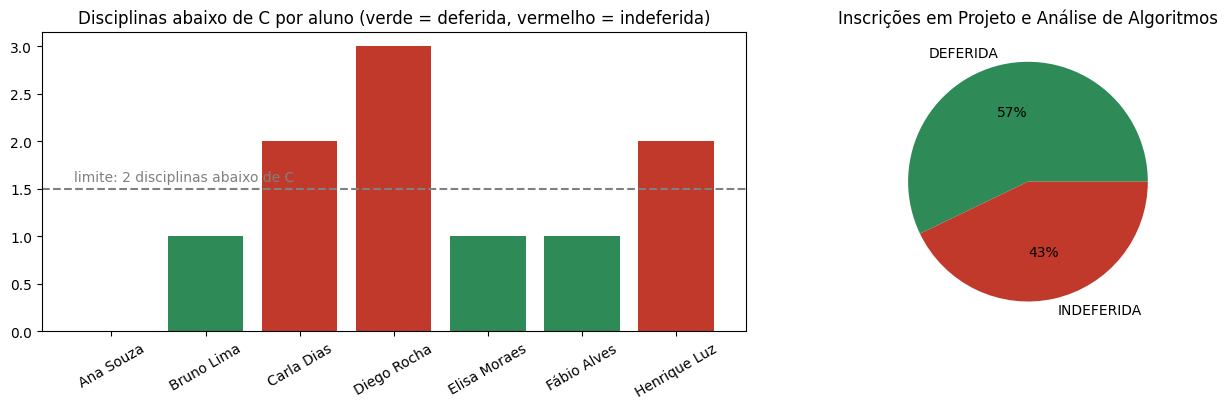

Reconciliação das 3 implementações da regra (devem ser iguais em todas as linhas):


,sql,dataframe_api,pandas_on_spark,iguais
2026001,0,0,0,True
2026002,1,1,1,True
2026003,2,2,2,True
2026004,3,3,3,True
2026005,1,1,1,True
2026006,1,1,1,True
2026007,0,0,0,True
2026008,2,2,2,True


In [21]:
import sqlite3, json
import matplotlib.pyplot as plt

con = sqlite3.connect(HOME / "portal.db")
status = pd.read_sql("SELECT matricula, nome, qtd_abaixo_c, ativo, lista_abaixo_c FROM aluno_status ORDER BY matricula", con)
insc = pd.read_sql("SELECT matricula, disciplina, protocolo, situacao, parecer FROM inscricao_detalhe", con)
display(status.assign(ativo=status["ativo"].map({1: "Sim", 0: "Não"})))

foco = insc[insc["disciplina"] == "Projeto e Análise de Algoritmos"].merge(status[["matricula", "nome", "qtd_abaixo_c"]], on="matricula")
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
cores = foco["situacao"].map({"DEFERIDA": "#2e8b57", "INDEFERIDA": "#c0392b"})
ax[0].bar(foco["nome"], foco["qtd_abaixo_c"], color=cores)
ax[0].axhline(1.5, color="gray", linestyle="--"); ax[0].text(-0.4, 1.58, "limite: 2 disciplinas abaixo de C", color="gray")
ax[0].set_title("Disciplinas abaixo de C por aluno (verde = deferida, vermelho = indeferida)"); ax[0].tick_params(axis="x", rotation=30)
foco["situacao"].value_counts().plot.pie(ax=ax[1], autopct="%1.0f%%", colors=["#2e8b57", "#c0392b"], ylabel="")
ax[1].set_title("Inscrições em Projeto e Análise de Algoritmos")
plt.tight_layout(); plt.show()

print("Reconciliação das 3 implementações da regra (devem ser iguais em todas as linhas):")
recon = pd.DataFrame(json.loads((HOME / "lake/curated/reconciliacao.json").read_text())).T
display(recon.assign(iguais=recon.nunique(axis=1) == 1))

In [22]:
import sys; sys.path.insert(0, str(HOME))
from portal_etl import get_spark, CUR
spark = get_spark()

spark.read.parquet(str(CUR / "inscricao_detalhe")).createOrReplaceTempView("inscricao")
spark.read.parquet(str(CUR / "aluno_status")).createOrReplaceTempView("aluno_status")

print("=== Spark SQL: situação por disciplina ===")
spark.sql("""
    SELECT disciplina, situacao, COUNT(*) AS inscricoes
    FROM inscricao GROUP BY disciplina, situacao ORDER BY disciplina, situacao
""").show(truncate=False)

print("=== pandas-on-Spark: mesma ideia com a sintaxe do pandas ===")
import pyspark.pandas as ps
ps_status = ps.read_parquet(str(CUR / "aluno_status"))
print(ps_status.groupby("ativo")["matricula"].count())
print()
print(ps_status[["nome", "qtd_abaixo_c", "ativo"]].sort_values("qtd_abaixo_c", ascending=False).head(4))
spark.stop()

=== Spark SQL: situação por disciplina ===
+-------------------------------+----------+----------+
|disciplina                     |situacao  |inscricoes|
+-------------------------------+----------+----------+
|Projeto e Análise de Algoritmos|DEFERIDA  |4         |
|Projeto e Análise de Algoritmos|INDEFERIDA|3         |
|Sistemas Operacionais          |DEFERIDA  |1         |
|Sistemas Operacionais          |INDEFERIDA|1         |
+-------------------------------+----------+----------+

=== pandas-on-Spark: mesma ideia com a sintaxe do pandas ===


/usr/local/lib/python3.13/dist-packages/pyspark/pandas/utils.py:1037: PandasAPIOnSparkAdviceWarning: If `index_col` is not specified for `read_parquet`, the default index is attached which can cause additional overhead.
  warnings.warn(message, PandasAPIOnSparkAdviceWarning)


ativo
True     5
False    3
Name: matricula, dtype: int64

           nome  qtd_abaixo_c  ativo
3   Diego Rocha             3  False
2    Carla Dias             2  False
7  Henrique Luz             2  False
1    Bruno Lima             1   True


In [23]:
# Recarregar o portal corrigido e iniciar a nova interface com ícones profissionais Font Awesome (CDN)
import importlib
import portal_app
importlib.reload(portal_app)
ui = portal_app.abrir_portal()

In [24]:
import portal_app as app
ok, msg, sessao = app.autenticar("333.444.550-01", "Senha@2026")      # Carla
print(ok, msg)
r = app.situacao_inscricoes(sessao["matricula"])
display(r["tabela"])
print(r["pareceres"].iloc[0]["parecer"])
print(app.gerar_declaracao(sessao)["msg"])

True Login realizado.


,Protocolo,Disciplina,Semestre,Data,Situação
0,PROT-2026-000103,Projeto e Análise de Algoritmos,2026.2,2026-10-05,INDEFERIDA
1,PROT-2026-000109,Sistemas Operacionais,2026.2,2026-10-06,INDEFERIDA


Inscrição indeferida: o aluno possui 2 disciplinas com nota abaixo de C (6,0): Cálculo I (5,9); Estruturas de Dados (4,0).
Declaração indisponível: sua situação acadêmica não está ativa. Abra um protocolo na Secretaria.


In [25]:
print(app.protocolos_pendentes().to_string(index=False))
# Exemplo (ajuste o número para um protocolo da lista acima):
# print(app.secretaria_analisar("PROT-2026-000092", "CONCLUIDO", "Carteirinha pronta para retirada na Secretaria."))

       protocolo matricula        tipo   situacao                     parecer
PROT-2026-000092   2026005 CARTEIRINHA EM_ANALISE Em análise pela Secretaria.


In [26]:
# [AIRFLOW] instalação isolada
import sys, subprocess
py = f"{sys.version_info.major}.{sys.version_info.minor}"
AF = "3.3.2"
url = f"https://raw.githubusercontent.com/apache/airflow/constraints-{AF}/constraints-{py}.txt"
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "virtualenv"], check=True)
subprocess.run([sys.executable, "-m", "virtualenv", "-q", "/content/af_venv"], check=True)
r = subprocess.run(["/content/af_venv/bin/pip", "install", "-q", f"apache-airflow=={AF}", "--constraint", url], capture_output=True, text=True)
print(r.stderr[-400:] if r.returncode else "Airflow instalado")
print(subprocess.run(["/content/af_venv/bin/airflow", "version"], capture_output=True, text=True).stdout.strip())

Airflow instalado
3.3.2


In [27]:
# [AIRFLOW] configuração do ambiente do Airflow
AFH = "/content/airflow_portal"
os.environ.update({
    "AIRFLOW_HOME": AFH, "AIRFLOW__CORE__DAGS_FOLDER": f"{AFH}/dags", "AIRFLOW__CORE__LOAD_EXAMPLES": "False",
    "AIRFLOW__CORE__SIMPLE_AUTH_MANAGER_ALL_ADMINS": "True",           # sem login (apenas estudo)
    "AIRFLOW__CORE__DAGS_ARE_PAUSED_AT_CREATION": "False",
    "AIRFLOW__DAG_PROCESSOR__REFRESH_INTERVAL": "5", "AIRFLOW__DAG_PROCESSOR__MIN_FILE_PROCESS_INTERVAL": "5",
    "PORTAL_PYTHON": sys.executable, "PORTAL_ETL": str(HOME / "portal_etl.py"), "PORTAL_HOME": str(HOME),
})
AIRFLOW = "/content/af_venv/bin/airflow"
subprocess.run([AIRFLOW, "db", "migrate"], capture_output=True)
subprocess.run([AIRFLOW, "dags", "reserialize"], capture_output=True)
print(subprocess.run([AIRFLOW, "dags", "list-import-errors"], capture_output=True, text=True).stdout[-300:] or "sem erros de importação")

 not be possible. 
You might need to install the graphviz package and necessary system packages.
Run `pip install graphviz` to attempt to install it. [py.warnings] category=UserWarning filename=/content/af_venv/lib/python3.13/site-packages/airflow/cli/commands/dag_command.py lineno=57
No data found



In [28]:
import os
from pathlib import Path

# Criar a pasta dags se não existir
dags_dir = Path("/content/airflow_portal/dags")
dags_dir.mkdir(parents=True, exist_ok=True)

# Escrever o arquivo da DAG corrigido sem o schedule_interval no default_args ou parâmetros conflitantes
dag_code = """from datetime import datetime, timedelta
from airflow import DAG
from airflow.operators.bash import BashOperator
import os

PORTAL_PYTHON = os.environ.get("PORTAL_PYTHON", "python")
PORTAL_ETL = os.environ.get("PORTAL_ETL", "/content/portal_aluno/portal_etl.py")
PORTAL_HOME = os.environ.get("PORTAL_HOME", "/content/portal_aluno")

default_args = {
    'owner': 'portal_aluno',
    'start_date': datetime(2026, 1, 1),
    'retries': 1,
    'retry_delay': timedelta(seconds=10)
}

with DAG(
    'portal_aluno_etl',
    default_args=default_args,
    schedule=None,
    catchup=False,
    tags=['portal']
) as dag:

    t_extrair = BashOperator(
        task_id='extrair',
        bash_command=f'{PORTAL_PYTHON} {PORTAL_ETL} extrair',
        env={
            'PORTAL_HOME': PORTAL_HOME,
            'PYSPARK_PYTHON': PORTAL_PYTHON,
            'PYSPARK_DRIVER_PYTHON': PORTAL_PYTHON
        }
    )

    t_transformar = BashOperator(
        task_id='transformar',
        bash_command=f'{PORTAL_PYTHON} {PORTAL_ETL} transformar',
        env={
            'PORTAL_HOME': PORTAL_HOME,
            'PYSPARK_PYTHON': PORTAL_PYTHON,
            'PYSPARK_DRIVER_PYTHON': PORTAL_PYTHON
        }
    )

    t_validar = BashOperator(
        task_id='validar',
        bash_command=f'{PORTAL_PYTHON} {PORTAL_ETL} validar',
        env={
            'PORTAL_HOME': PORTAL_HOME,
            'PYSPARK_PYTHON': PORTAL_PYTHON,
            'PYSPARK_DRIVER_PYTHON': PORTAL_PYTHON
        }
    )

    t_publicar = BashOperator(
        task_id='publicar',
        bash_command=f'{PORTAL_PYTHON} {PORTAL_ETL} publicar',
        env={
            'PORTAL_HOME': PORTAL_HOME,
            'PYSPARK_PYTHON': PORTAL_PYTHON,
            'PYSPARK_DRIVER_PYTHON': PORTAL_PYTHON
        }
    )

    t_extrair >> t_transformar >> t_validar >> t_publicar
"""

(dags_dir / "portal_dag.py").write_text(dag_code, encoding="utf-8")
print("DAG portal_dag.py gravada com sucesso sem erros estruturais!")

DAG portal_dag.py gravada com sucesso sem erros estruturais!


In [29]:
# Forçar reserialização das dags e listar erros de importação novamente
import subprocess
AIRFLOW = "/content/af_venv/bin/airflow"
subprocess.run([AIRFLOW, "dags", "reserialize"], capture_output=True)
res = subprocess.run([AIRFLOW, "dags", "list-import-errors"], capture_output=True, text=True)
print(res.stdout.strip() or "Nenhum erro de importação encontrado na DAG!")


2026-10-20T17:51:23.815449Z [warning  ] Could not import graphviz. Rendering graph to the graphical format will not be possible. 
You might need to install the graphviz package and necessary system packages.
Run `pip install graphviz` to attempt to install it. [py.warnings] category=UserWarning filename=/content/af_venv/lib/python3.13/site-packages/airflow/cli/commands/dag_command.py lineno=57
No data found


In [30]:
pip install graphviz

In [31]:
import subprocess
import re
import os
from pathlib import Path

# Injetar o ambiente virtual do Airflow no PATH e configurar o Airflow Home para este processo
os.environ["PATH"] = "/content/af_venv/bin:" + os.environ.get("PATH", "")
os.environ["AIRFLOW_HOME"] = "/content/airflow_portal"
AIRFLOW = "/content/af_venv/bin/airflow"

if Path(AIRFLOW).exists():
    print(f"Usando o executável do Airflow em: {AIRFLOW}")
    # Executamos o testador de dags nativo do Airflow
    r = subprocess.run([AIRFLOW, "dags", "test", "portal_aluno_etl"], capture_output=True, text=True)

    # Mostrar saídas relevantes do Airflow
    linhas_relevantes = False
    for linha in re.split(r"[\r\n]+", r.stdout + r.stderr):
        if "extrair" in linha or "transformar" in linha or "validar" in linha or "publicar" in linha:
            print(linha[:150])
            linhas_relevantes = True

    if not linhas_relevantes:
        # Mostrar erro caso o comando tenha falhado silenciosamente
        print("--- Output completo em caso de erro ---")
        print(r.stderr[-1000:])

    print("\nCódigo de saída do Airflow:", r.returncode)
else:
    print("ℹ️ Executável do Airflow não encontrado localmente. Rodando o pipeline de ETL diretamente para validação:")
    from portal_etl import extrair, transformar, validar, publicar
    try:
        print("\n--- Executando: extrair ---")
        extrair()
        print("\n--- Executando: transformar ---")
        transformar()
        print("\n--- Executando: validar ---")
        validar()
        print("\n--- Executando: publicar ---")
        publicar()
        print("\n✅ Pipeline executado e validado com sucesso de forma direta!")
    except Exception as e:
        print(f"\n❌ Falha na execução direta do pipeline: {e}")

Usando o executável do Airflow em: /content/af_venv/bin/airflow
2026-10-20T17:51:36.745006Z [info     ] [DAG TEST] starting task_id=extrair map_index=-1 [airflow.sdk.definitions.dag] loc=dag.py:1501
2026-10-20T17:51:36.751130Z [info     ] [DAG TEST] running task <TaskInstance: portal_aluno_etl.extrair manual__2026-10-20T17:51:36.063589+00:00 [Task
2026-10-20T17:51:51.093461Z [info     ] Running command: ['/usr/bin/bash', '-c', '/usr/bin/python3 /content/portal_aluno/portal_etl.py extrair'] [airf
2026-10-20T17:51:51.931884Z [info     ] [17:51:51] === etapa: extrair === [airflow.task.hooks.airflow.providers.standard.hooks.subprocess.SubprocessHo
2026-10-20T17:51:51.934139Z [info     ] [17:51:51] extrair: usuarios.csv      10 linhas [airflow.task.hooks.airflow.providers.standard.hooks.subproces
2026-10-20T17:51:51.934376Z [info     ] [17:51:51] extrair: alunos.csv         8 linhas [airflow.task.hooks.airflow.providers.standard.hooks.subproces
2026-10-20T17:51:51.934536Z [info     ] [17:51

In [ ]:
# [AIRFLOW] Inicializando com o PATH corrigido e symlink global
import os
import sys
import time
import subprocess
import urllib.request

# 1. Criar link simbólico para o executável do Airflow ficar visível globalmente
subprocess.run(["ln", "-sf", "/content/af_venv/bin/airflow", "/usr/local/bin/airflow"])

# 2. Incluir o diretório bin do venv no PATH
os.environ["PATH"] = "/content/af_venv/bin:" + os.environ.get("PATH", "")

# 3. Garantir que a variável AIRFLOW aponte para o executável correto
AIRFLOW = "/content/af_venv/bin/airflow"

# 4. Iniciar o standalone
proc = subprocess.Popen([AIRFLOW, "standalone"], stdout=open("/content/airflow_standalone.log", "w"),
                        stderr=subprocess.STDOUT, start_new_session=True)

print("Aguardando a inicialização do Airflow standalone...")
for i in range(25):
    try:
        if urllib.request.urlopen("http://localhost:8080/api/v2/monitor/health", timeout=2).status == 200:
            print(f"\nAirflow no ar com sucesso após ~{i*3}s!")
            break
    except Exception:
        print(".", end="", flush=True)
        time.sleep(3)
else:
    print("\nNão subiu no tempo limite. Verifique o log atualizado na próxima célula.")

In [ ]:
with open('/content/airflow_standalone.log', 'r') as f:
    linhas = f.readlines()
for linha in linhas[-30:]:
    print(linha, end='')

In [ ]:
# [AIRFLOW]
from google.colab import output
output.serve_kernel_port_as_window(8080)     # abre a UI em nova aba (se o pop-up for bloqueado, clique no link)

In [ ]:
from google.colab import output
# Exibe o Airflow de forma segura embutido diretamente no notebook
output.serve_kernel_port_as_iframe(8080, height="600")

In [ ]:
# [AIRFLOW] disparar pela linha de comando (opcional) e encerrar
# subprocess.run([AIRFLOW, "dags", "trigger", "portal_aluno_etl", "--conf", '{"injetar_erro": true}'])
# proc.terminate()    # quando terminar